# Proyecto BI – Equipo 5: Recursos Humanos
## Análisis de rotación de empleados (IBM HR Analytics Employee Attrition)
**Curso:** Análisis de Datos – ITM 2026-2

**Fuente:** IBM HR Analytics Employee Attrition & Performance (Kaggle):
https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

**Notebook 1 de 2:** Fase 1 (comprensión), Fase 3 (preparación) y EDA. Continúa en `02_hipotesis_kpis.ipynb`. La fase 5 (dashboard) se construye en Power BI a partir de `data/hr_attrition_clean.csv`, que genera este mismo notebook.

# Fase 1. Comprensión del problema
**Contexto.** El dataset tiene 1.470 empleados y 35 variables: datos demográficos (edad, género, estado civil), laborales (departamento, cargo, nivel, horas extra, viajes), de compensación (ingreso mensual, % de aumento, opciones de acciones), de antigüedad y de satisfacción (encuestas de 1 a 4). La variable objetivo es `Attrition`, que indica si el empleado dejó la empresa.

**Problema de negocio.** La rotación voluntaria es costosa: reclutar, capacitar y la productividad que se pierde pueden costar entre el 50 % y el 200 % del salario anual de quien se va. Recursos Humanos necesita saber **quién se va, por qué y dónde actuar primero**.

**Preguntas clave**
1. ¿Cuál es la tasa de rotación y cómo cambia por departamento, cargo y nivel?
2. ¿Hacer horas extra aumenta la probabilidad de salida?
3. ¿Los empleados que se van ganan menos que los que se quedan?
4. ¿La satisfacción laboral y el balance vida-trabajo se relacionan con la rotación?
5. ¿En qué etapa de su antigüedad se va más gente?

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='Set2')
pd.set_option('display.max_columns', 50)

df_raw = pd.read_csv('../data/WA_Fn-UseC_-HR-Employee-Attrition.csv', encoding='utf-8-sig')
print(df_raw.shape)
df_raw.head()

(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [2]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

# Fase 3. Preparación y modelado de datos
### 3.1 Calidad de datos

In [3]:
print('Nulos totales:', df_raw.isna().sum().sum())
print('Duplicados:', df_raw.duplicated().sum())
print('Columnas constantes:', [c for c in df_raw if df_raw[c].nunique()==1])
print('IDs únicos:', df_raw.EmployeeNumber.is_unique)

Nulos totales: 0
Duplicados: 0
Columnas constantes: ['EmployeeCount', 'Over18', 'StandardHours']
IDs únicos: True


**Decisiones de limpieza**
- No hay nulos ni filas duplicadas.
- Se eliminan `EmployeeCount`, `Over18` y `StandardHours` porque tienen un solo valor y no aportan información.
- `DailyRate`, `HourlyRate` y `MonthlyRate` no tienen relación clara con `MonthlyIncome` (variables sintéticas del dataset), así que no se usan en el análisis.
- Las escalas de 1 a 4 se traducen a etiquetas en español para el dashboard.
- Se crean variables derivadas: `Rotacion` (0/1), rangos de edad, de ingreso y de antigüedad, e índice de satisfacción.

In [4]:
df = df_raw.drop(columns=['EmployeeCount','Over18','StandardHours'])
df['Rotacion'] = (df.Attrition=='Yes').astype(int)

esc_sat = {1:'Baja',2:'Media',3:'Alta',4:'Muy alta'}
esc_edu = {1:'Bachillerato',2:'Técnico',3:'Pregrado',4:'Maestría',5:'Doctorado'}
esc_wlb = {1:'Malo',2:'Regular',3:'Bueno',4:'Excelente'}
for c in ['EnvironmentSatisfaction','JobSatisfaction','RelationshipSatisfaction','JobInvolvement']:
    df[c+'_Txt'] = df[c].map(esc_sat)
df['WorkLifeBalance_Txt'] = df.WorkLifeBalance.map(esc_wlb)
df['Education_Txt'] = df.Education.map(esc_edu)
df['Attrition_Txt'] = df.Attrition.map({'Yes':'Se fue','No':'Activo'})
df['OverTime_Txt'] = df.OverTime.map({'Yes':'Sí','No':'No'})
df['Department_Txt'] = df.Department.map({'Sales':'Ventas','Research & Development':'I+D','Human Resources':'RR.HH.'})
df['BusinessTravel_Txt'] = df.BusinessTravel.map({'Non-Travel':'No viaja','Travel_Rarely':'Viaja poco','Travel_Frequently':'Viaja frecuente'})
df['Gender_Txt'] = df.Gender.map({'Male':'Hombre','Female':'Mujer'})
df['MaritalStatus_Txt'] = df.MaritalStatus.map({'Single':'Soltero','Married':'Casado','Divorced':'Divorciado'})

df['RangoEdad'] = pd.cut(df.Age,[17,25,35,45,55,61],labels=['18-25','26-35','36-45','46-55','56-60'])
df['RangoIngreso'] = pd.qcut(df.MonthlyIncome,4,labels=['Q1 Bajo','Q2 Medio-bajo','Q3 Medio-alto','Q4 Alto'])
df['RangoAntiguedad'] = pd.cut(df.YearsAtCompany,[-1,2,5,10,40],labels=['0-2 años','3-5 años','6-10 años','>10 años'])
df['IndiceSatisfaccion'] = df[['EnvironmentSatisfaction','JobSatisfaction','RelationshipSatisfaction','WorkLifeBalance']].mean(axis=1).round(2)
df['AniosSinPromocion'] = df.YearsSinceLastPromotion
df.shape

(1470, 50)

### 3.2 Dimensiones y métricas
| Tipo | Campos |
|---|---|
| **Dimensiones** | Departamento, Cargo (JobRole), Nivel, Género, Estado civil, Rango de edad, Rango de ingreso, Rango de antigüedad, Horas extra, Viajes, Educación, Satisfacción |
| **Métricas** | Conteo de empleados, Rotación (0/1), Ingreso mensual, % aumento salarial, Años en la empresa, Años sin promoción, Índice de satisfacción, Distancia al trabajo |

Para Power BI se exporta una sola tabla plana (`hr_attrition_clean.csv`), que funciona como tabla de hechos con las dimensiones desnormalizadas. Para 1.470 filas es el modelo más simple y suficiente.

In [5]:
df.to_csv('../data/hr_attrition_clean.csv', index=False, encoding='utf-8-sig')
print('Exportado data/hr_attrition_clean.csv', df.shape)

Exportado data/hr_attrition_clean.csv (1470, 50)


## Análisis exploratorio (EDA)

Tasa de rotación global: 16.1%  (237 de 1470)


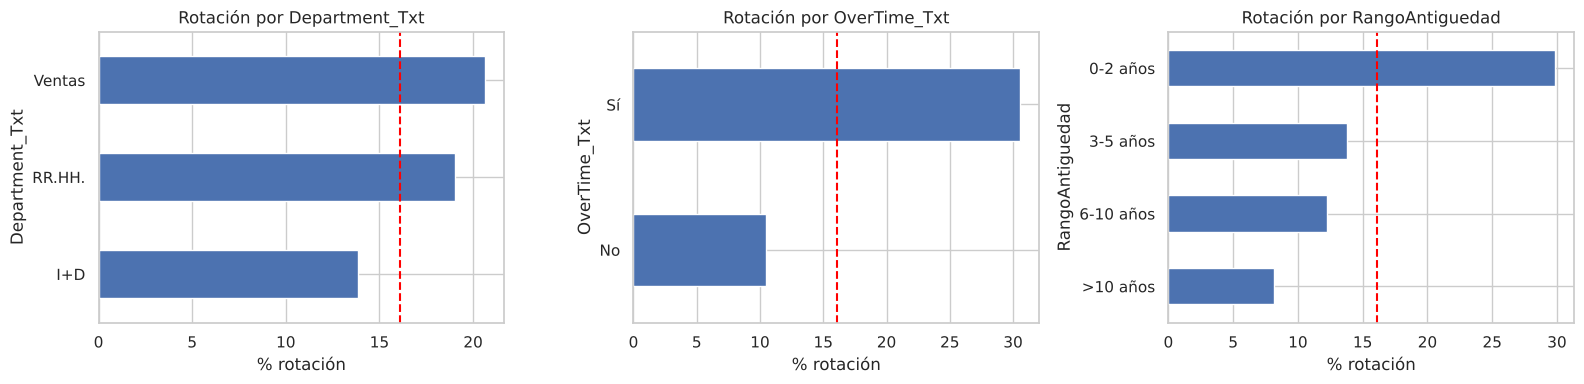

In [6]:
tasa = df.Rotacion.mean()
print(f'Tasa de rotación global: {tasa:.1%}  ({df.Rotacion.sum()} de {len(df)})')
fig, ax = plt.subplots(1,3, figsize=(16,4))
for a, col in zip(ax, ['Department_Txt','OverTime_Txt','RangoAntiguedad']):
    (df.groupby(col, observed=True).Rotacion.mean()*100).sort_values().plot.barh(ax=a, color='#4C72B0')
    a.set_xlabel('% rotación'); a.set_title(f'Rotación por {col}'); a.axvline(tasa*100, ls='--', c='r')
plt.tight_layout(); plt.show()

In [7]:
rol = df.groupby('JobRole').agg(Empleados=('Rotacion','size'), Salidas=('Rotacion','sum'), Tasa=('Rotacion','mean')).sort_values('Tasa', ascending=False)
rol['Tasa'] = (rol.Tasa*100).round(1); rol

,Empleados,Salidas,Tasa
JobRole,,,
Sales Representative,83,33,39.8
Laboratory Technician,259,62,23.9
Human Resources,52,12,23.1
Sales Executive,326,57,17.5
Research Scientist,292,47,16.1
Manufacturing Director,145,10,6.9
Healthcare Representative,131,9,6.9
Manager,102,5,4.9
Research Director,80,2,2.5


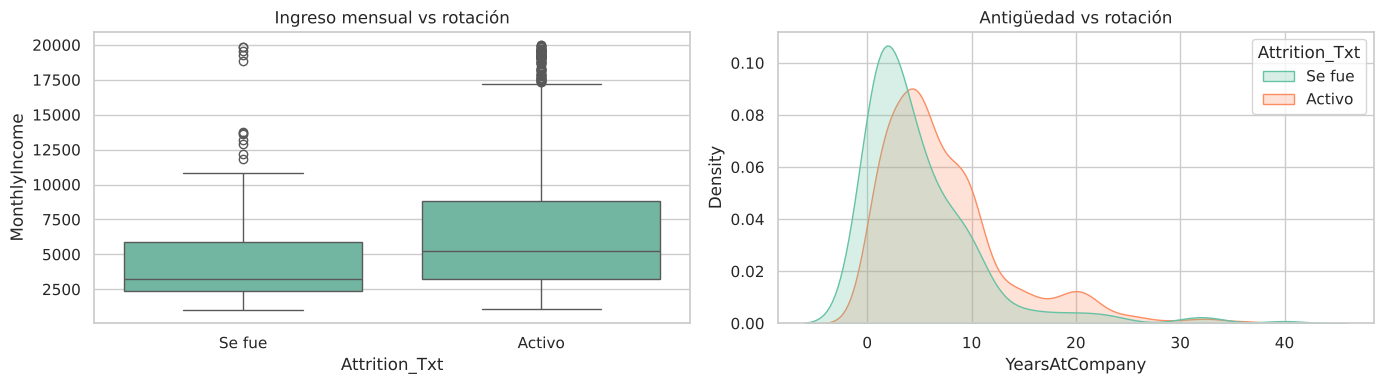

In [8]:
fig, ax = plt.subplots(1,2, figsize=(14,4))
sns.boxplot(data=df, x='Attrition_Txt', y='MonthlyIncome', ax=ax[0]); ax[0].set_title('Ingreso mensual vs rotación')
sns.kdeplot(data=df, x='YearsAtCompany', hue='Attrition_Txt', common_norm=False, fill=True, ax=ax[1]); ax[1].set_title('Antigüedad vs rotación')
plt.tight_layout(); plt.show()

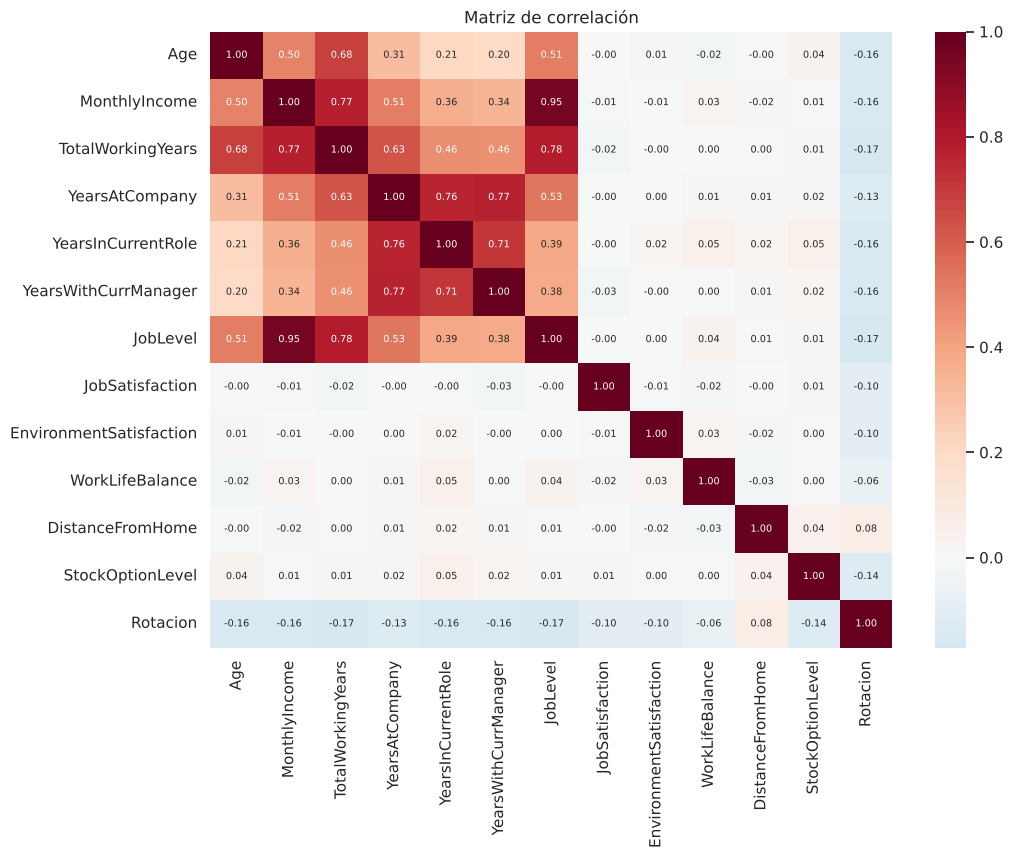

In [9]:
num = ['Age','MonthlyIncome','TotalWorkingYears','YearsAtCompany','YearsInCurrentRole','YearsWithCurrManager',
       'JobLevel','JobSatisfaction','EnvironmentSatisfaction','WorkLifeBalance','DistanceFromHome','StockOptionLevel','Rotacion']
plt.figure(figsize=(11,8)); sns.heatmap(df[num].corr(), cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size':7})
plt.title('Matriz de correlación'); plt.show()